# Difusión en miniatura: entrenar y generar paso a paso

Cada dato es un punto $(x, y)$ en el plano, y el dataset son 2000 puntos que dibujan un corazón. Así cada paso se puede ver en una sola gráfica.

El plan tiene dos mitades:

1. **Entrenamiento.** Ensuciamos los puntos con ruido y enseñamos a una red a adivinar qué ruido se les puso.
2. **Inferencia.** Partimos de ruido puro y usamos la red para quitarlo poco a poco hasta que aparece un corazón nuevo.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import HTML
from matplotlib import animation
from sklearn.neural_network import MLPRegressor

rng = np.random.default_rng(42)
NARANJA, PIZARRA, GRIS = "#FF5900", "#262C34", "#BBBBBB"


def plano(ax, titulo=""):
    ax.set_xlim(-3.5, 3.5)
    ax.set_ylim(-3.5, 3.5)
    ax.set_aspect("equal")
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_title(titulo, fontsize=10)

## 1. El dataset

Puntos sobre la curva del corazón, con un poco de grosor. Están escalados para que su desviación ronde 1, la misma escala del ruido que vamos a sumar.

forma del dataset: (2000, 2)
primeros 3 puntos:
 [[-1.96  0.87]
 [ 0.07 -1.87]
 [-0.95  1.49]]


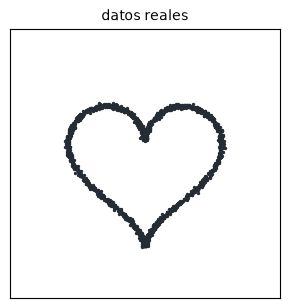

In [2]:
N = 2000
s = rng.uniform(0, 2 * np.pi, N)
X0 = np.c_[16 * np.sin(s) ** 3, 13 * np.cos(s) - 5 * np.cos(2 * s) - 2 * np.cos(3 * s) - np.cos(4 * s)] / 8
X0 += 0.03 * rng.standard_normal(X0.shape)

print("forma del dataset:", X0.shape)
print("primeros 3 puntos:\n", X0[:3].round(2))

fig, ax = plt.subplots(figsize=(3.5, 3.5))
ax.scatter(*X0.T, s=2, color=PIZARRA)
plano(ax, "datos reales")
plt.show()

## 2. El horario de ruido

Usamos $T=50$ pasos. En el paso $t$ entra una dosis de ruido $\beta_t$, que crece de $0.001$ a $0.2$. Lo que interesa es $\bar\alpha_t$, la fracción de señal que sobrevive hasta el paso $t$. Con ella se salta directamente a cualquier paso:

$$x_t=\sqrt{\bar\alpha_t}\,x_0+\sqrt{1-\bar\alpha_t}\,\epsilon,\qquad \epsilon\sim\mathcal N(0,I).$$

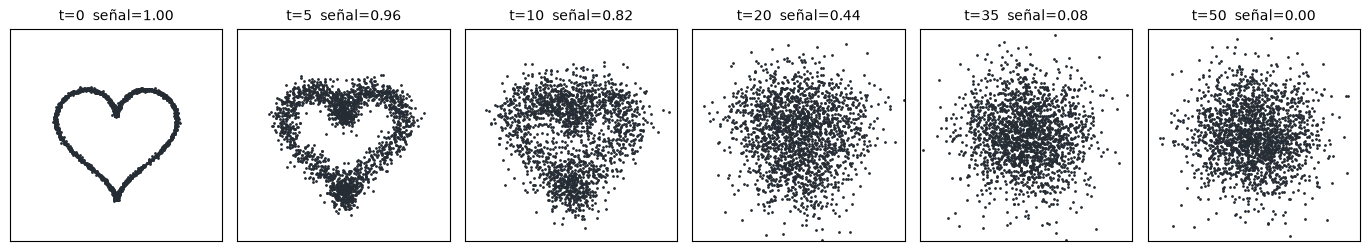

In [3]:
T = 50
betas = np.linspace(1e-3, 0.2, T)
alphas = 1 - betas
alpha_barra = np.cumprod(alphas)


def ensuciar(x0, t, eps):
    # t va de 1 a T; los arreglos se indexan desde 0
    a = alpha_barra[t - 1][:, None]
    return np.sqrt(a) * x0 + np.sqrt(1 - a) * eps


mostrar = [0, 5, 10, 20, 35, 50]
fig, axes = plt.subplots(1, len(mostrar), figsize=(2.3 * len(mostrar), 2.6))
eps = rng.standard_normal(X0.shape)
for ax, t in zip(axes, mostrar):
    xt = X0 if t == 0 else ensuciar(X0, np.full(N, t), eps)
    ax.scatter(*xt.T, s=1, color=PIZARRA)
    señal = 1.0 if t == 0 else alpha_barra[t - 1]
    plano(ax, f"t={t}  señal={señal:.2f}")
plt.tight_layout()
plt.show()

## 3. La tarea de la red

La red recibe un punto ruidoso $x_t$ y el paso $t$, y tiene que devolver el ruido $\epsilon$ que se le sumó. Es una regresión común y corriente:

| entrada | salida esperada |
|---|---|
| $x_t$ (2 números) y $t$ | $\epsilon$ (2 números) |

Veamos cinco ejemplos de entrenamiento tal cual se los damos.

In [4]:
def entrada(xt, t):
    # El paso t entra como t/T y dos rasgos periódicos, para que la red lo distinga con facilidad
    tt = t[:, None] / T
    return np.c_[xt, tt, np.sin(np.pi * tt), np.cos(np.pi * tt)]


idx = rng.choice(N, 5, replace=False)
t_ej = rng.integers(1, T + 1, 5)
eps_ej = rng.standard_normal((5, 2))
xt_ej = ensuciar(X0[idx], t_ej, eps_ej)

print(f"{'x0':>16} {'t':>4} {'eps (objetivo)':>18} {'xt (entrada)':>18}")
for a, t, e, b in zip(X0[idx], t_ej, eps_ej, xt_ej):
    print(f"({a[0]:+.2f}, {a[1]:+.2f}) {t:>4}   ({e[0]:+.2f}, {e[1]:+.2f})   ({b[0]:+.2f}, {b[1]:+.2f})")

              x0    t     eps (objetivo)       xt (entrada)
(+0.07, -2.15)   24   (+0.65, +1.07)   (+0.59, -0.29)
(-1.19, -0.85)   40   (-0.09, -0.24)   (-0.30, -0.39)
(-1.62, -0.36)    1   (+0.52, -0.26)   (-1.61, -0.37)
(-0.00, +0.61)   18   (-0.34, +1.04)   (-0.24, +1.16)
(+0.08, -1.88)   47   (+1.26, +1.08)   (+1.26, +0.90)


## 4. Entrenamiento

Cada época repite la receta de arriba con todo el dataset: un $t$ al azar y un $\epsilon$ nuevo para cada punto. Luego un paso de descenso por gradiente sobre el error cuadrático $\lVert\epsilon-\hat\epsilon\rVert^2$. La red es un perceptrón multicapa con dos capas ocultas de 128 neuronas.

época    0: pérdida = 0.4053
época  300: pérdida = 0.1728
época  600: pérdida = 0.1664
época  900: pérdida = 0.1522
época 1200: pérdida = 0.1582
época 1499: pérdida = 0.1730


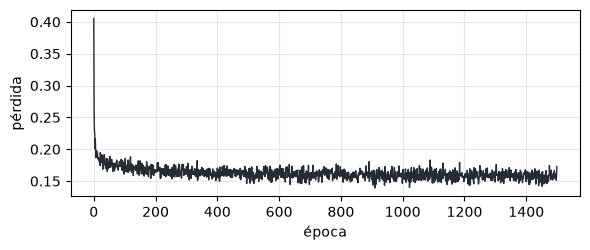

In [5]:
red = MLPRegressor(hidden_layer_sizes=(128, 128), learning_rate_init=1e-3, random_state=42)
EPOCAS = 1500
perdidas = []
for epoca in range(EPOCAS):
    t = rng.integers(1, T + 1, N)
    eps = rng.standard_normal((N, 2))
    red.partial_fit(entrada(ensuciar(X0, t, eps), t), eps)
    perdidas.append(red.loss_)
    if epoca % 300 == 0 or epoca == EPOCAS - 1:
        print(f"época {epoca:>4}: pérdida = {red.loss_:.4f}")

fig, ax = plt.subplots(figsize=(6, 2.6))
ax.plot(perdidas, color=PIZARRA, lw=1)
ax.set_xlabel("época")
ax.set_ylabel("pérdida")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

La pérdida no baja a cero. Con mucho ruido el punto original es casi irrecuperable, así que la red solo puede acertar en promedio. Aun así aprende la dirección correcta.

Para verlo, tomamos una rejilla de puntos y dibujamos $-\hat\epsilon$, la dirección en que cada punto se mueve al restarle el ruido que predice la red. Las flechas tienen el mismo largo para que se lea solo la dirección. Con poco ruido ($t=5$) apuntan a la parte más cercana de la curva. Con mucho ruido ($t=45$) apuntan al centro del corazón: el punto ya perdió casi toda su información y la mejor apuesta es el promedio de los datos. Por eso la inferencia primero junta los puntos y al final los reparte sobre la curva.

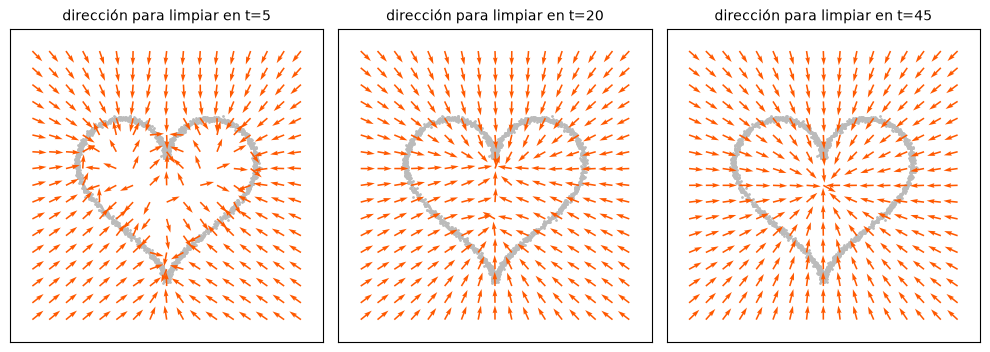

In [6]:
g = np.linspace(-3, 3, 17)
GX, GY = np.meshgrid(g, g)
rejilla = np.c_[GX.ravel(), GY.ravel()]

fig, axes = plt.subplots(1, 3, figsize=(10, 3.5))
for ax, t in zip(axes, [5, 20, 45]):
    eps_hat = red.predict(entrada(rejilla, np.full(len(rejilla), t)))
    ax.scatter(*X0.T, s=1, color=GRIS)
    direccion = -eps_hat / np.linalg.norm(eps_hat, axis=1, keepdims=True)
    ax.quiver(*rejilla.T, *direccion.T, color=NARANJA, angles="xy", scale=22, width=0.005)
    plano(ax, f"dirección para limpiar en t={t}")
plt.tight_layout()
plt.show()

## 5. Inferencia: un solo paso, desmenuzado

Arrancamos de ruido puro $x_T\sim\mathcal N(0,I)$. En cada paso la red estima el ruido, lo restamos en la proporción que dicta el horario y sumamos una pizca de ruido fresco (salvo en el último paso):

$$x_{t-1}=\frac{1}{\sqrt{\alpha_t}}\left(x_t-\frac{\beta_t}{\sqrt{1-\bar\alpha_t}}\,\hat\epsilon\right)+\sqrt{\beta_t}\,z.$$

Primero un solo punto en el paso $t=T$.

In [7]:
def paso_atras(x, t, z):
    eps_hat = red.predict(entrada(x, np.full(len(x), t)))
    media = (x - betas[t - 1] / np.sqrt(1 - alpha_barra[t - 1]) * eps_hat) / np.sqrt(alphas[t - 1])
    if t > 1:
        return media + np.sqrt(betas[t - 1]) * z, eps_hat
    return media, eps_hat


x = rng.standard_normal((1, 2))
z = rng.standard_normal((1, 2))
x_nuevo, eps_hat = paso_atras(x, T, z)
print("x_T                :", x.round(3))
print("ruido estimado     :", eps_hat.round(3))
print("ruido fresco z     :", z.round(3))
print("x_{T-1}            :", x_nuevo.round(3))

x_T                : [[-3.311  0.748]]
ruido estimado     : [[-3.268  0.686]]
ruido fresco z     : [[-1.619 -0.194]]
x_{T-1}            : [[-3.694  0.596]]


## 6. Inferencia completa

Ahora 2000 puntos de ruido y los 50 pasos. Guardamos cada paso para la animación y seguimos la trayectoria de cinco puntos.

forma de la historia: (51, 2000, 2)


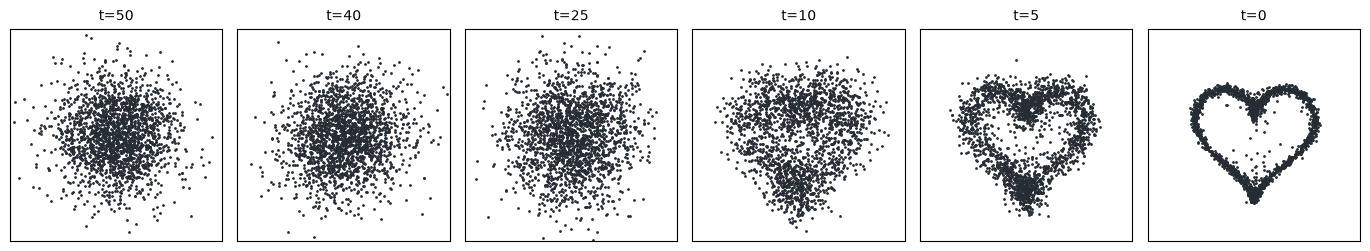

In [8]:
x = rng.standard_normal((N, 2))
historia = [x.copy()]
for t in range(T, 0, -1):
    x, _ = paso_atras(x, t, rng.standard_normal(x.shape))
    historia.append(x.copy())
historia = np.array(historia)  # forma (T+1, N, 2): historia[k] es el estado tras k pasos
print("forma de la historia:", historia.shape)

mostrar = [0, 10, 25, 40, 45, 50]
fig, axes = plt.subplots(1, len(mostrar), figsize=(2.3 * len(mostrar), 2.6))
for ax, k in zip(axes, mostrar):
    ax.scatter(*historia[k].T, s=1, color=PIZARRA)
    plano(ax, f"t={T - k}")
plt.tight_layout()
plt.show()

In [9]:
fig, ax = plt.subplots(figsize=(4, 4), dpi=80)
nube = ax.scatter(*historia[0].T, s=2, color=PIZARRA)
plano(ax)


def dibujar(k):
    nube.set_offsets(historia[k])
    ax.set_title(f"inferencia, t = {T - k}", fontsize=10)
    return [nube]


anim = animation.FuncAnimation(fig, dibujar, frames=len(historia), interval=120)
plt.close(fig)
HTML(anim.to_jshtml())

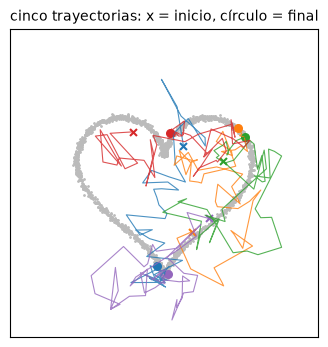

In [10]:
fig, ax = plt.subplots(figsize=(4, 4))
ax.scatter(*X0.T, s=1, color=GRIS)
for i, color in zip(range(5), plt.cm.tab10.colors):
    camino = historia[:, i]
    ax.plot(*camino.T, color=color, lw=0.8, alpha=0.8)
    ax.scatter(*camino[0], color=color, s=25, marker="x")
    ax.scatter(*camino[-1], color=color, s=30)
plano(ax, "cinco trayectorias: x = inicio, círculo = final")
plt.show()

## 7. Resultado

A la izquierda los datos reales, a la derecha puntos generados desde ruido. La red nunca vio estos puntos: los fabricó quitando ruido paso a paso.

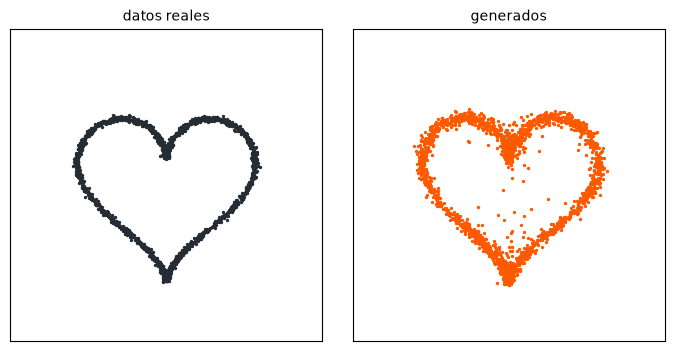

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(7, 3.5))
axes[0].scatter(*X0.T, s=2, color=PIZARRA)
plano(axes[0], "datos reales")
axes[1].scatter(*historia[-1].T, s=2, color=NARANJA)
plano(axes[1], "generados")
plt.tight_layout()
plt.show()